In [14]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv

TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 



In [15]:
EURO_DATA = {
    "0.01 EUR": {
        "value": 0.01,
        "diameter": 16.26, # Diámetro en mm
    },
    "0.02 EUR": {
        "value": 0.02,
        "diameter": 18.75,
    },
    "0.05 EUR": {
        "value": 0.05,
        "diameter": 21.25,
    },
    "0.10 EUR": {
        "value": 0.10,
        "diameter": 19.75,
    },
    "0.20 EUR": {
        "value": 0.20,
        "diameter": 22.25,
    },
    "0.50 EUR": {
        "value": 0.50,
        "diameter": 24.25,
    },
    "1 EUR": {
        "value": 1.00,
        "diameter": 23.25,
    },
    "2 EUR": {
        "value": 2.00,
        "diameter": 25.75,
    },
}

In [16]:
def plot_img(img, title="Monedas", cmap=None):
    plt.figure(figsize=(10, 10))
    plt.imshow(img, cmap=cmap)
    if title:
        plt.title(title)
    plt.show()

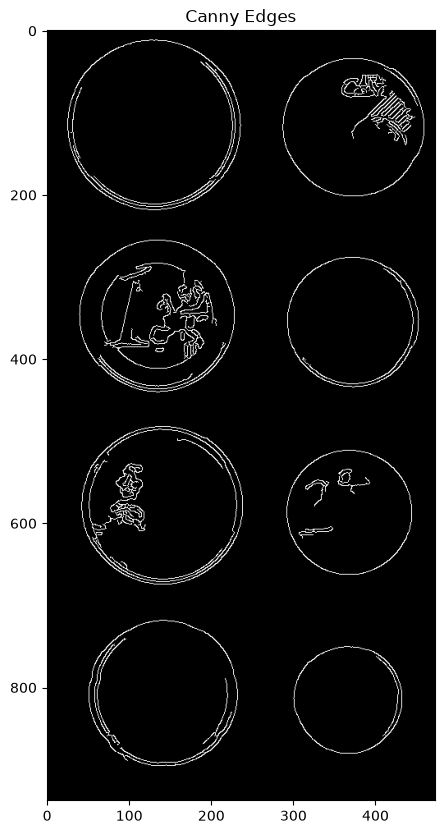

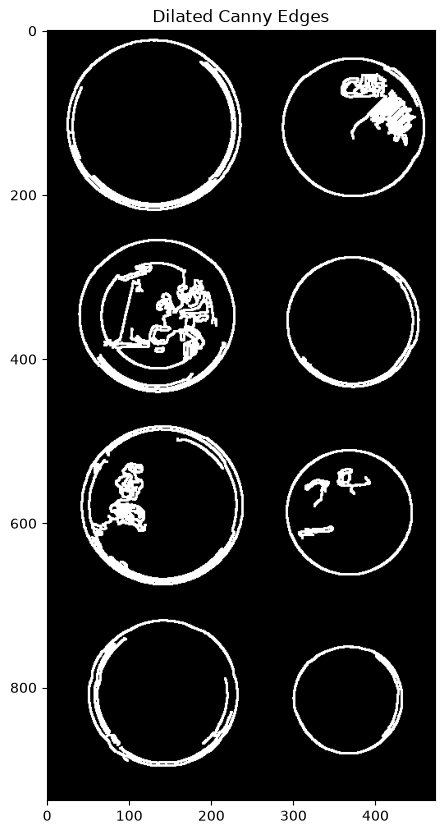

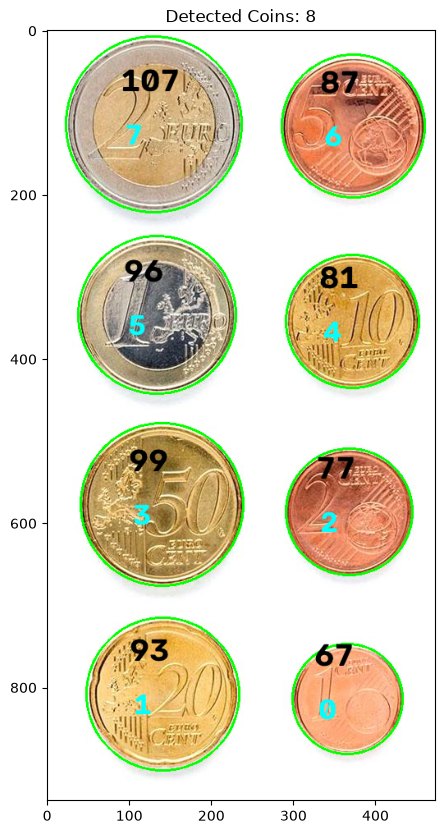

In [17]:
def plot_coin_detection_for(img_with_coin: cv2.Mat, debug=False) -> tuple[list[tuple[int, int, int, int]], cv2.Mat]:
    coin_gray = cv2.cvtColor(img_with_coin, cv2.COLOR_BGR2GRAY)
    coin_blur = cv2.GaussianBlur(coin_gray, (7, 7), 0)
    coin_canny = cv2.Canny(coin_blur, 30, 255)

    if debug:
        plot_img(coin_canny, title="Canny Edges", cmap='gray')

    kernel = np.ones((3, 3), np.uint8)
    canny_dilated = cv2.dilate(coin_canny, kernel, iterations=1)
    if debug:
        plot_img(canny_dilated, title="Dilated Canny Edges", cmap='gray')

    contour_image = img_with_coin.copy()
    contour, heirarchy = cv2.findContours(canny_dilated.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    coin_rgb = cv2.cvtColor(img_with_coin, cv2.COLOR_BGR2RGB)
    cv2.drawContours(contour_image, contour, -1, (0,255,0), 2)

    counted_coins = 0
    detected_coin_list: list[tuple[int, int, int, int]] = []
    counted_coins_img = coin_rgb.copy()

    AREA_THRESHOLD_VALUE = 1000
    PERIMETER_THRESHOLD_VALUE = 0.46
    for coin in contour:
        # Determinar si es una moneda mediante área y perímetro
        area = cv2.contourArea(coin)
        if area < AREA_THRESHOLD_VALUE:
            continue
        
        perimeter = cv2.arcLength(coin, True)
        if perimeter == 0:
            continue
        
        circularity = 4 * np.pi * area / (perimeter * perimeter)
        if circularity < PERIMETER_THRESHOLD_VALUE:
            continue
        
        (x, y), radius = cv2.minEnclosingCircle(coin)
        x, y, radius = int(x), int(y), int(radius)
        diameter = radius * 2
        counted_coins += 1
        detected_coin_list.append((x, y, radius, diameter))

        # Dibujar radio e indice de moneda detectada
        cv2.circle(counted_coins_img, (x, y), radius, (0, 255, 0), 2)
        cv2.putText(counted_coins_img, str(radius), (x-40, y-40), cv2.FONT_HERSHEY_SIMPLEX, 1.3, (0,0,0), 2)
        cv2.putText(counted_coins_img, str(counted_coins-1), (x-35, y+25), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 255), 2)

    if debug:
        plot_img(counted_coins_img, title=f"Detected Coins: {counted_coins}", cmap=None)

    return detected_coin_list, counted_coins_img

coin_img = cv2.imread('Monedas.jpg')
detected_coins, _ = plot_coin_detection_for(coin_img, debug=True)

In [18]:
def calibrate_with_known_coin(coins, coin_id, known_diameter_mm=23.25): # 1€ Por Defecto
    if coin_id < 0 or coin_id >= len(coins):
        print(f"Coin ID {coin_id} not found.")
        return False, 0
    
    (x, y, radius, diameter_px) = coins[coin_id]
    pixel_to_mm_ratio = known_diameter_mm / diameter_px
    
    print(f"--- Calibration Successful ---")
    print(f"Reference Coin ID : {coin_id}")
    print(f"Measured in image : {diameter_px} pixels (radius = {radius} px)")
    print(f"Real physical size: {known_diameter_mm:.2f} mm")
    print(f"Scale factor      : {pixel_to_mm_ratio:.4f} mm/pixel")
    print(f"                    ({1 / pixel_to_mm_ratio:.2f} pixels/mm)")
    
    return True, pixel_to_mm_ratio


print("Input the coin ID to calibrate with a 1.00€ coin:")
coin_ref = int(input("Enter coin ID (e.g., '1 EUR'): "))
calibrated, pixel_to_mm_ratio = calibrate_with_known_coin(detected_coins, coin_ref)

Input the coin ID to calibrate with a 1.00€ coin:
--- Calibration Successful ---
Reference Coin ID : 5
Measured in image : 192 pixels (radius = 96 px)
Real physical size: 23.25 mm
Scale factor      : 0.1211 mm/pixel
                    (8.26 pixels/mm)



--- Coin Classification Results ---
Coin 0: 134px -> 16.23mm -> Classified as 0.01 EUR (diff: 0.03mm)
Coin 1: 186px -> 22.52mm -> Classified as 0.20 EUR (diff: 0.27mm)
Coin 2: 154px -> 18.65mm -> Classified as 0.02 EUR (diff: 0.10mm)
Coin 3: 198px -> 23.98mm -> Classified as 0.50 EUR (diff: 0.27mm)
Coin 4: 162px -> 19.62mm -> Classified as 0.10 EUR (diff: 0.13mm)
Coin 5: 192px -> 23.25mm -> Classified as 1 EUR (diff: 0.00mm)
Coin 6: 174px -> 21.07mm -> Classified as 0.05 EUR (diff: 0.18mm)
Coin 7: 214px -> 25.91mm -> Classified as 2 EUR (diff: 0.16mm)
-----------------------------------
Total Amount Present: 3.88 €

Breakdown:
  0.01 EUR: 1x
  0.02 EUR: 1x
  0.05 EUR: 1x
  0.10 EUR: 1x
  0.20 EUR: 1x
  0.50 EUR: 1x
  1 EUR: 1x
  2 EUR: 1x


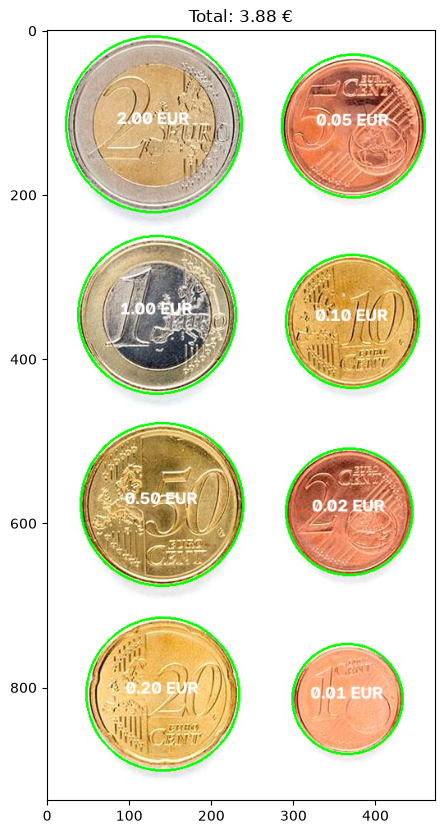

In [19]:
def classify_and_sum_coins(coins, pixel_to_mm_ratio, img_rgb, debug=False):
    total_amount = 0.0
    counts = {k: 0 for k in EURO_DATA}
    annotated_img = img_rgb.copy()

    def debug_print(msg: str):
        if not debug:
            return
        print(msg)
    
    debug_print("\n--- Coin Classification Results ---")
    for i, (x, y, radius, diameter_px) in enumerate(coins):
        # Encontramos diametro en mm
        diameter_mm = diameter_px * pixel_to_mm_ratio
        
        # Encontramos el mejor aproximado al valor real
        best_coin = min(EURO_DATA.items(), key=lambda item: abs(diameter_mm - item[1]["diameter"]))
        coin_name, coin_info = best_coin
        
        value = coin_info["value"]
        total_amount += value
        counts[coin_name] += 1
        
        diff = abs(diameter_mm - coin_info["diameter"])
        debug_print(f"Coin {i}: {diameter_px}px -> {diameter_mm:.2f}mm -> Classified as {coin_name} (diff: {diff:.2f}mm)")
        
        cv2.circle(annotated_img, (x, y), radius, (0, 255, 0), 2)
        cv2.putText(annotated_img, f"{value:.2f} EUR", (x - 45, y), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255,255,255), 2)
    
    debug_print("-----------------------------------")
    debug_print(f"Total Amount Present: {total_amount:.2f} €\n")
    debug_print("Breakdown:")
    for coin_name, cnt in counts.items():
        if cnt > 0:
            debug_print(f"  {coin_name}: {cnt}x")

    if debug:     
        plot_img(annotated_img, title=f"Total: {total_amount:.2f} €")
    return total_amount, counts, annotated_img

if calibrated:
    coin_to_rgb = cv2.cvtColor(coin_img, cv2.COLOR_BGR2RGB)
    total_val, coin_counts, _ = classify_and_sum_coins(detected_coins, pixel_to_mm_ratio, coin_to_rgb, debug=True)


In [20]:
def live_calibration_init():
    vid = cv2.VideoCapture(0)
    while True:
        ret, frame = vid.read()
        if not ret:
            break

        test_frame = frame.copy()
        cv2.putText(test_frame, "Press C to start calibration", (50, 50), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0,0,0), 2)
        cv2.imshow("Calibration Frame", test_frame)

        key = cv2.waitKey(1) & 0xFF
        if key == ord('c'):
            print("Calibration started...")
            return frame.copy(), vid

    return None, None

In [21]:
def live_coin_detection(coins, video, px_to_mm_ratio):
    count = 0
    while True:
        ret, frame = video.read()
        if not ret:
            break

        total_frame = frame.copy()
        live_coins, annotated_img = plot_coin_detection_for(total_frame)
        coin_to_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
        total_val, coin_counts, value_img = classify_and_sum_coins(live_coins, px_to_mm_ratio, coin_to_rgb)
        coin_count = sum(coin_counts.values())
        cv2.putText(value_img, f"Total: {total_val} (Monedas: {coin_count})", (10, 50), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0,0,255), 2)

        y = 100
        for _, (k,v) in enumerate(coin_counts.items()):
            cv2.putText(value_img, f"{k}: {v}", (10, y), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (255,0,0), 2)
            y += 50

        cv2.imshow("Live Coin Detection", value_img)

        if cv2.waitKey(1) == 27:
            break

Calibration started...


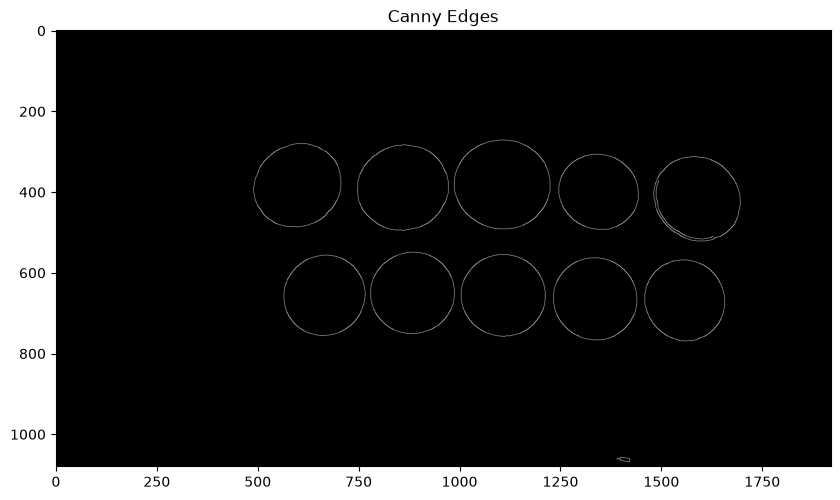

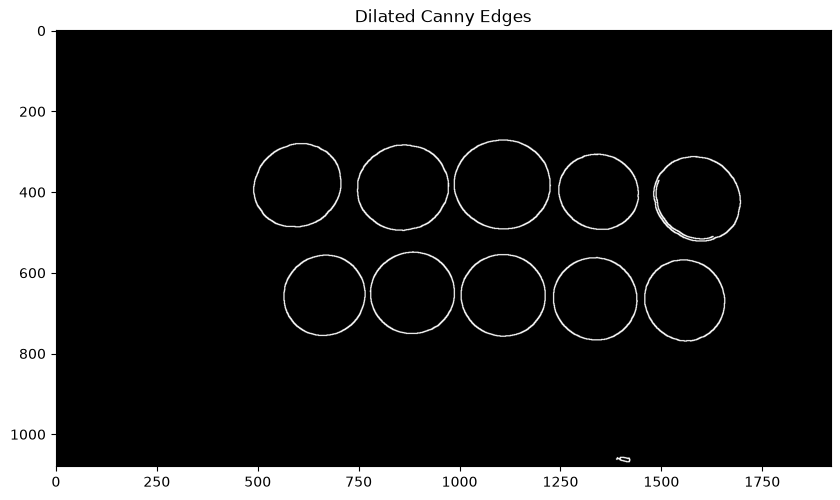

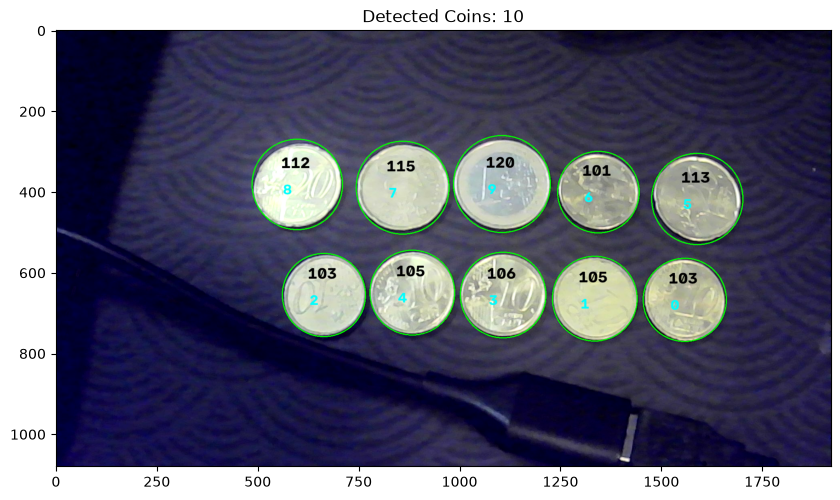

Input the coin ID to calibrate with a 1.00€ coin:
--- Calibration Successful ---
Reference Coin ID : 9
Measured in image : 240 pixels (radius = 120 px)
Real physical size: 23.25 mm
Scale factor      : 0.0969 mm/pixel
                    (10.32 pixels/mm)


In [22]:
def run_live_coin_detection():
    # 1 - Activar la camara y esperar a comenzar calibracion (tecla C)
    coin_frame, video = live_calibration_init()
    if coin_frame is None or video is None:
        print("Could not run calibration correctly")
        return

    # 2 - Capturar ultimo frame, dibujar indices de monedas y escoger moneda de 1€ de calibracion
    live_coins, annotated_img = plot_coin_detection_for(coin_frame, debug=True)

    # 3 - Preguntar al usuario para escoger la moneda correcta
    print("Input the coin ID to calibrate with a 1.00€ coin:")
    coin_ref = int(input("Enter coin ID (e.g., '1 EUR'): "))
    did_calibrate, pxtmm_ratio = calibrate_with_known_coin(live_coins, coin_ref)
    if not did_calibrate:
        print("Could not calibrate correctly.")
        return

    # 4 - Empezar deteccion en vivo
    live_coin_detection(live_coins, video, pxtmm_ratio)

run_live_coin_detection()

division entre area y perimetro

https://www.kaggle.com/code/mariamalkuwaiti/opencv-coin-detection-and-counting

https://dev.to/tinazhouhui/coin-detection-discovering-opencv-with-python-1ka1

https://www.youtube.com/watch?v=_Coth4YESzk&list=UULFTiWJJhaH6BviSWKLJUM9sg